TensorFlow: 2.21.0
Đang tải IMDb từ Keras...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "context_aware_sentiment"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ token_ids           │ (None, 160)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_mask (Lambda) │ (None, 160)       │          0 │ token_ids[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 160, 64)   │  1,280,000 │ token_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pair_mask (Lambda)  │ (None, 160, 160)  │          0 │ token_mask[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention      │ [(None, 160, 64), │     16,640 │ embedding[0][0],  │
│ (MultiHeadAttentio… │ (None, 2, 160,    │            │ embedding[0][0],  │
│                     │ 160)]             │            │ pair_mask[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 160, 64)   │          0 │ embedding[0][0],  │
│                     │                   │            │ self_attention[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 160, 64)   │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ context_vector      │ (None, 64)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │ token_mask[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,160 │ context_vector[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         65 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,300,993 (4.96 MB)

 Trainable params: 1,300,993 (4.96 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
106/106 - 54s - 505ms/step - accuracy: 0.7620 - loss: 0.4736 - val_accuracy: 0.8493 - val_loss: 0.3547
Epoch 2/3
106/106 - 82s - 776ms/step - accuracy: 0.9044 - loss: 0.2423 - val_accuracy: 0.8120 - val_loss: 0.5214
Epoch 3/3
106/106 - 50s - 472ms/step - accuracy: 0.9216 - loss: 0.1973 - val_accuracy: 0.8213 - val_loss: 0.4921

Test subset (5000 reviews): loss=0.5005, accuracy=0.8152, F1=0.8285
Training time: 185.9 seconds


,Sentence,Expected sentiment,Prediction,Predicted-class probability,Correct
0,I like this movie.,positive,positive,0.9867,True
1,I do not like this movie.,negative,negative,0.8570,True
2,"I thought this movie would be bad, but it was ...",positive,positive,0.9890,True


Test summary: accuracy=0.8152, F1=0.8285, training time=185.9s


,Sentence,Token,Mean attention weight
0,I like this movie.,<START>,0.19955
1,I like this movie.,i,0.20036
2,I like this movie.,like,0.20036
3,I like this movie.,this,0.19926
4,I like this movie.,movie,0.20046
5,I do not like this movie.,<START>,0.14251
6,I do not like this movie.,i,0.14300
7,I do not like this movie.,do,0.14295
8,I do not like this movie.,not,0.14316
9,I do not like this movie.,like,0.14300


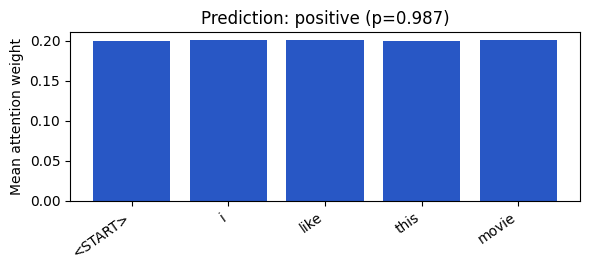

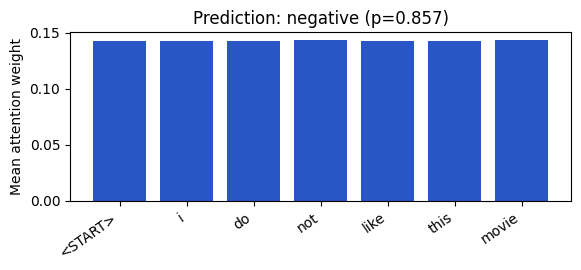

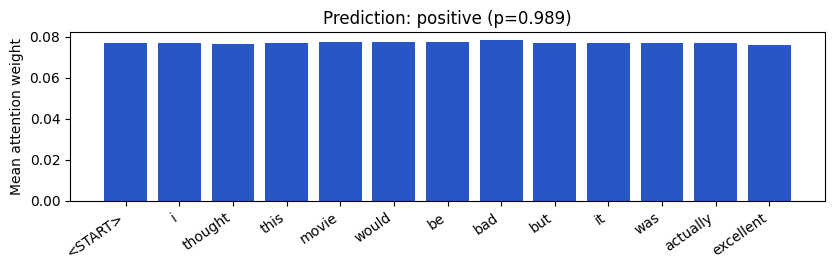

In [ ]:
# Bài 26 — Application: Context-aware sentiment
# AI assistance statement: ChatGPT Codex generated the notebook boilerplate, model/training code, inference and visualization; adapted to the three prompt sentences and verified by running this notebook in Colab.
# Attention weights are descriptive model outputs; they do not by themselves establish why a prediction was made.

import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import text_to_word_sequence
from tensorflow.keras import layers, Model

SEED = 26
np.random.seed(SEED)
tf.random.set_seed(SEED)
MAX_WORDS, MAX_LEN, EMBED_DIM, NUM_HEADS = 20000, 160, 64, 2
print('TensorFlow:', tf.__version__)
print('Đang tải IMDb từ Keras...')
(x_train_raw, y_train), (x_test_raw, y_test) = imdb.load_data(num_words=MAX_WORDS)
word_index = imdb.get_word_index()
x_train = pad_sequences(x_train_raw, maxlen=MAX_LEN, padding='post', truncating='post')
x_test = pad_sequences(x_test_raw, maxlen=MAX_LEN, padding='post', truncating='post')
N_TRAIN, N_TEST = 15000, 5000
x_fit, y_fit = x_train[:N_TRAIN], np.asarray(y_train[:N_TRAIN])
x_eval, y_eval = x_test[:N_TEST], np.asarray(y_test[:N_TEST])

inputs = layers.Input(shape=(MAX_LEN,), dtype='int32', name='token_ids')
valid = layers.Lambda(lambda t: tf.not_equal(t, 0), output_shape=(MAX_LEN,), name='token_mask')(inputs)
pair_mask = layers.Lambda(lambda m: tf.logical_and(m[:, :, None], m[:, None, :]), output_shape=(MAX_LEN, MAX_LEN), name='pair_mask')(valid)
embedded = layers.Embedding(MAX_WORDS, EMBED_DIM, mask_zero=True, name='embedding')(inputs)
attention = layers.MultiHeadAttention(num_heads=NUM_HEADS, key_dim=EMBED_DIM // NUM_HEADS, dropout=0.1, name='self_attention')
attended, attention_scores = attention(embedded, embedded, attention_mask=pair_mask, return_attention_scores=True)
contextual = layers.LayerNormalization()(layers.Add()([embedded, attended]))
context = layers.GlobalAveragePooling1D(name='context_vector')(contextual, mask=valid)
hidden = layers.Dropout(0.25)(layers.Dense(64, activation='relu')(context))
positive_probability = layers.Dense(1, activation='sigmoid')(hidden)
model = Model(inputs, positive_probability, name='context_aware_sentiment')
attention_model = Model(inputs, [positive_probability, attention_scores])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()
start = time.time()
history = model.fit(x_fit, y_fit, epochs=3, batch_size=128, validation_split=0.1, shuffle=True, verbose=2)
training_seconds = time.time() - start
test_loss, test_accuracy = model.evaluate(x_eval, y_eval, batch_size=128, verbose=0)
test_probs = model.predict(x_eval, batch_size=128, verbose=0).ravel()
test_pred = (test_probs >= 0.5).astype('int32')
test_f1 = f1_score(y_eval, test_pred)
print(f'\nTest subset ({N_TEST} reviews): loss={test_loss:.4f}, accuracy={test_accuracy:.4f}, F1={test_f1:.4f}')
print(f'Training time: {training_seconds:.1f} seconds')

examples = ['I like this movie.', 'I do not like this movie.', 'I thought this movie would be bad, but it was actually excellent.']
expected = np.array(['positive', 'negative', 'positive'])
def encode_sentence(sentence):
    tokens = text_to_word_sequence(sentence)
    ids = [1] + [word_index.get(token, 2) + 3 for token in tokens]
    ids = [idx if idx < MAX_WORDS else 2 for idx in ids]
    return tokens[:MAX_LEN - 1], pad_sequences([ids], maxlen=MAX_LEN, padding='post', truncating='post')
encoded = [encode_sentence(s) for s in examples]
x_examples = np.vstack([item[1][0] for item in encoded])
example_probs, example_scores = attention_model.predict(x_examples, verbose=0)
predicted = np.where(example_probs.ravel() >= 0.5, 'positive', 'negative')
confidence = np.where(example_probs.ravel() >= 0.5, example_probs.ravel(), 1 - example_probs.ravel())
prediction_table = pd.DataFrame({'Sentence': examples, 'Expected sentiment': expected, 'Prediction': predicted, 'Predicted-class probability': confidence.round(4), 'Correct': predicted == expected})
display(prediction_table)
print(f'Test summary: accuracy={test_accuracy:.4f}, F1={test_f1:.4f}, training time={training_seconds:.1f}s')

attention_records = []
for i, (sentence, (tokens, _)) in enumerate(zip(examples, encoded)):
    labels = ['<START>'] + tokens
    count = len(labels)
    weights = example_scores[i, :, :count, :count].mean(axis=(0, 1))
    weights = weights / weights.sum()
    for token, weight in zip(labels, weights):
        attention_records.append({'Sentence': sentence, 'Token': token, 'Mean attention weight': round(float(weight), 5)})
attention_table = pd.DataFrame(attention_records)
display(attention_table)
for i, sentence in enumerate(examples):
    labels = ['<START>'] + encoded[i][0]
    count = len(labels)
    weights = example_scores[i, :, :count, :count].mean(axis=(0, 1))
    weights = weights / weights.sum()
    fig, ax = plt.subplots(figsize=(max(6, 0.65 * count), 2.8))
    ax.bar(range(count), weights, color='#2857C5')
    ax.set_xticks(range(count))
    ax.set_xticklabels(labels, rotation=35, ha='right')
    ax.set_ylabel('Mean attention weight')
    ax.set_title(f'Prediction: {predicted[i]} (p={confidence[i]:.3f})')
    fig.tight_layout()
    plt.show()

,Test index,Review (first 70 tokens),Expected,Prediction,Predicted-class probability,Correct
0,1,this film requires a lot of patience because i...,positive,positive,0.9998,True
1,0,please give this one a miss br br kristy swans...,negative,positive,0.9129,False


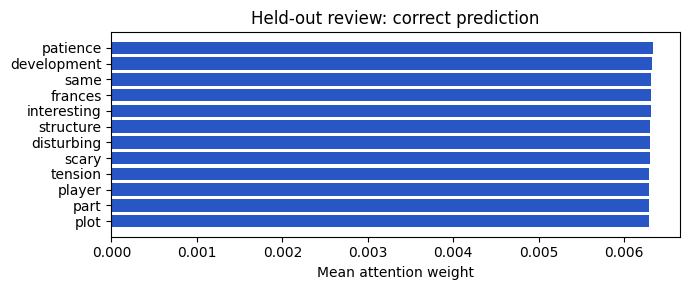

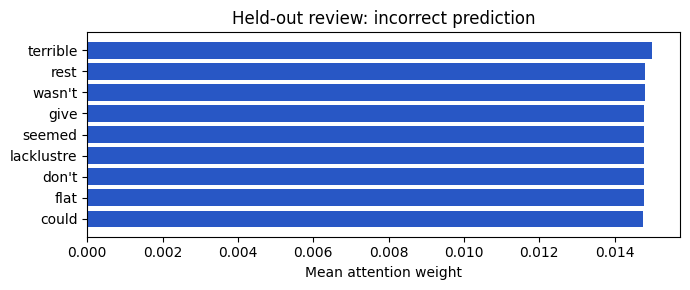

In [ ]:
# Chọn một ví dụ đúng và một ví dụ sai từ tập test để người học tự phân tích.
correct_idx = np.flatnonzero(test_pred == y_eval)
wrong_idx = np.flatnonzero(test_pred != y_eval)
selected = [int(correct_idx[0]), int(wrong_idx[0])]
inverse_word_index = {idx + 3: word for word, idx in word_index.items() if idx + 3 < MAX_WORDS}

def decode_review(encoded_review, max_words=70):
    words = []
    for token_id in encoded_review:
        token_id = int(token_id)
        if token_id == 0:
            break
        if token_id == 1:
            continue
        words.append(inverse_word_index.get(token_id, '<UNK>'))
        if len(words) >= max_words:
            break
    return ' '.join(words)

review_probability, review_scores = attention_model.predict(x_eval[selected], verbose=0)
review_predictions = (review_probability.ravel() >= 0.5).astype('int32')
review_rows = []
for j, idx in enumerate(selected):
    p = float(review_probability[j, 0])
    review_rows.append({
        'Test index': idx,
        'Review (first 70 tokens)': decode_review(x_test_raw[idx]),
        'Expected': 'positive' if y_eval[idx] else 'negative',
        'Prediction': 'positive' if review_predictions[j] else 'negative',
        'Predicted-class probability': round(p if review_predictions[j] else 1-p, 4),
        'Correct': bool(review_predictions[j] == y_eval[idx]),
    })
selected_review_table = pd.DataFrame(review_rows)
display(selected_review_table)

# Show top attention targets for these two examples; analysis is left to the student.
for j, idx in enumerate(selected):
    token_ids = x_eval[idx]
    count = int(np.count_nonzero(token_ids))
    labels = [inverse_word_index.get(int(t), '<UNK>') for t in token_ids[:count]]
    matrix = review_scores[j, :, :count, :count]
    weights = matrix.mean(axis=(0, 1))
    weights = weights / weights.sum()
    top = np.argsort(weights)[-12:]
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.barh([labels[k] for k in top], weights[top], color='#2857C5')
    ax.set_xlabel('Mean attention weight')
    ax.set_title(f"Held-out review: {'correct' if review_predictions[j] == y_eval[idx] else 'incorrect'} prediction")
    fig.tight_layout()
    plt.show()

In [ ]:
# Exact shortened text and largest token weights for the selected held-out examples.
for j, idx in enumerate(selected):
    correctness = 'correct' if review_predictions[j] == y_eval[idx] else 'incorrect'
    review_text = decode_review(x_test_raw[idx], max_words=45)
    print(f"{correctness.upper()} CASE | test index={idx} | expected={'positive' if y_eval[idx] else 'negative'} | predicted={'positive' if review_predictions[j] else 'negative'} | confidence={review_rows[j]['Predicted-class probability']:.4f}")
    print('Review excerpt:', review_text)
    token_ids = x_eval[idx]
    count = int(np.count_nonzero(token_ids))
    labels = [inverse_word_index.get(int(t), '<UNK>') for t in token_ids[:count]]
    weights = review_scores[j, :, :count, :count].mean(axis=(0, 1))
    weights = weights / weights.sum()
    top = np.argsort(weights)[-5:][::-1]
    print('Top mean-attention tokens:', ', '.join(f'{labels[k]}={weights[k]:.4f}' for k in top))

CORRECT CASE | test index=1 | expected=positive | predicted=positive | confidence=0.9998
Review excerpt: this film requires a lot of patience because it focuses on mood and character development the plot is very simple and many of the scenes take place on the same set in frances austen's the sandy dennis character apartment but the film builds to a
Top mean-attention tokens: patience=0.0063, development=0.0063, same=0.0063, frances=0.0063, interesting=0.0063
INCORRECT CASE | test index=0 | expected=negative | predicted=positive | confidence=0.9129
Review excerpt: please give this one a miss br br kristy swanson and the rest of the cast rendered terrible performances the show is flat flat flat br br i don't know how michael madison could have allowed this one on his plate he almost seemed to
Top mean-attention tokens: terrible=0.0150, rest=0.0148, wasn't=0.0148, give=0.0148, give=0.0148
